In [1]:
# SETUP: imports and plot style
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" and "ieee" styles)
from matplotlib.ticker import FuncFormatter

plt.style.use(["science", "ieee"])

# The figure was designed for 7.5 pt text; everything is scaled up to 10.5 pt
base_font_old = 7.5
base_font = 10.5
legend_font = 10.5
axis_label_font = 13.5
scale_factor = base_font / base_font_old

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": base_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": base_font,
    "ytick.labelsize": base_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [2]:
# REACTION-RATE MODELS: defined in reaction_kinetics.py (shared with Economics.ipynb)
# Rates in mol_CH4 / (kg_cat s); T in K; pressures given in bar.
import importlib
import reaction_kinetics
importlib.reload(reaction_kinetics)  # pick up edits to reaction_kinetics.py without a kernel restart
from reaction_kinetics import (
    draw_reaction_rates,
    rate_label,
    reaction_rate_carbon,
    reaction_rate_iron,
    reaction_rate_nickel,
    temperature_label,
)

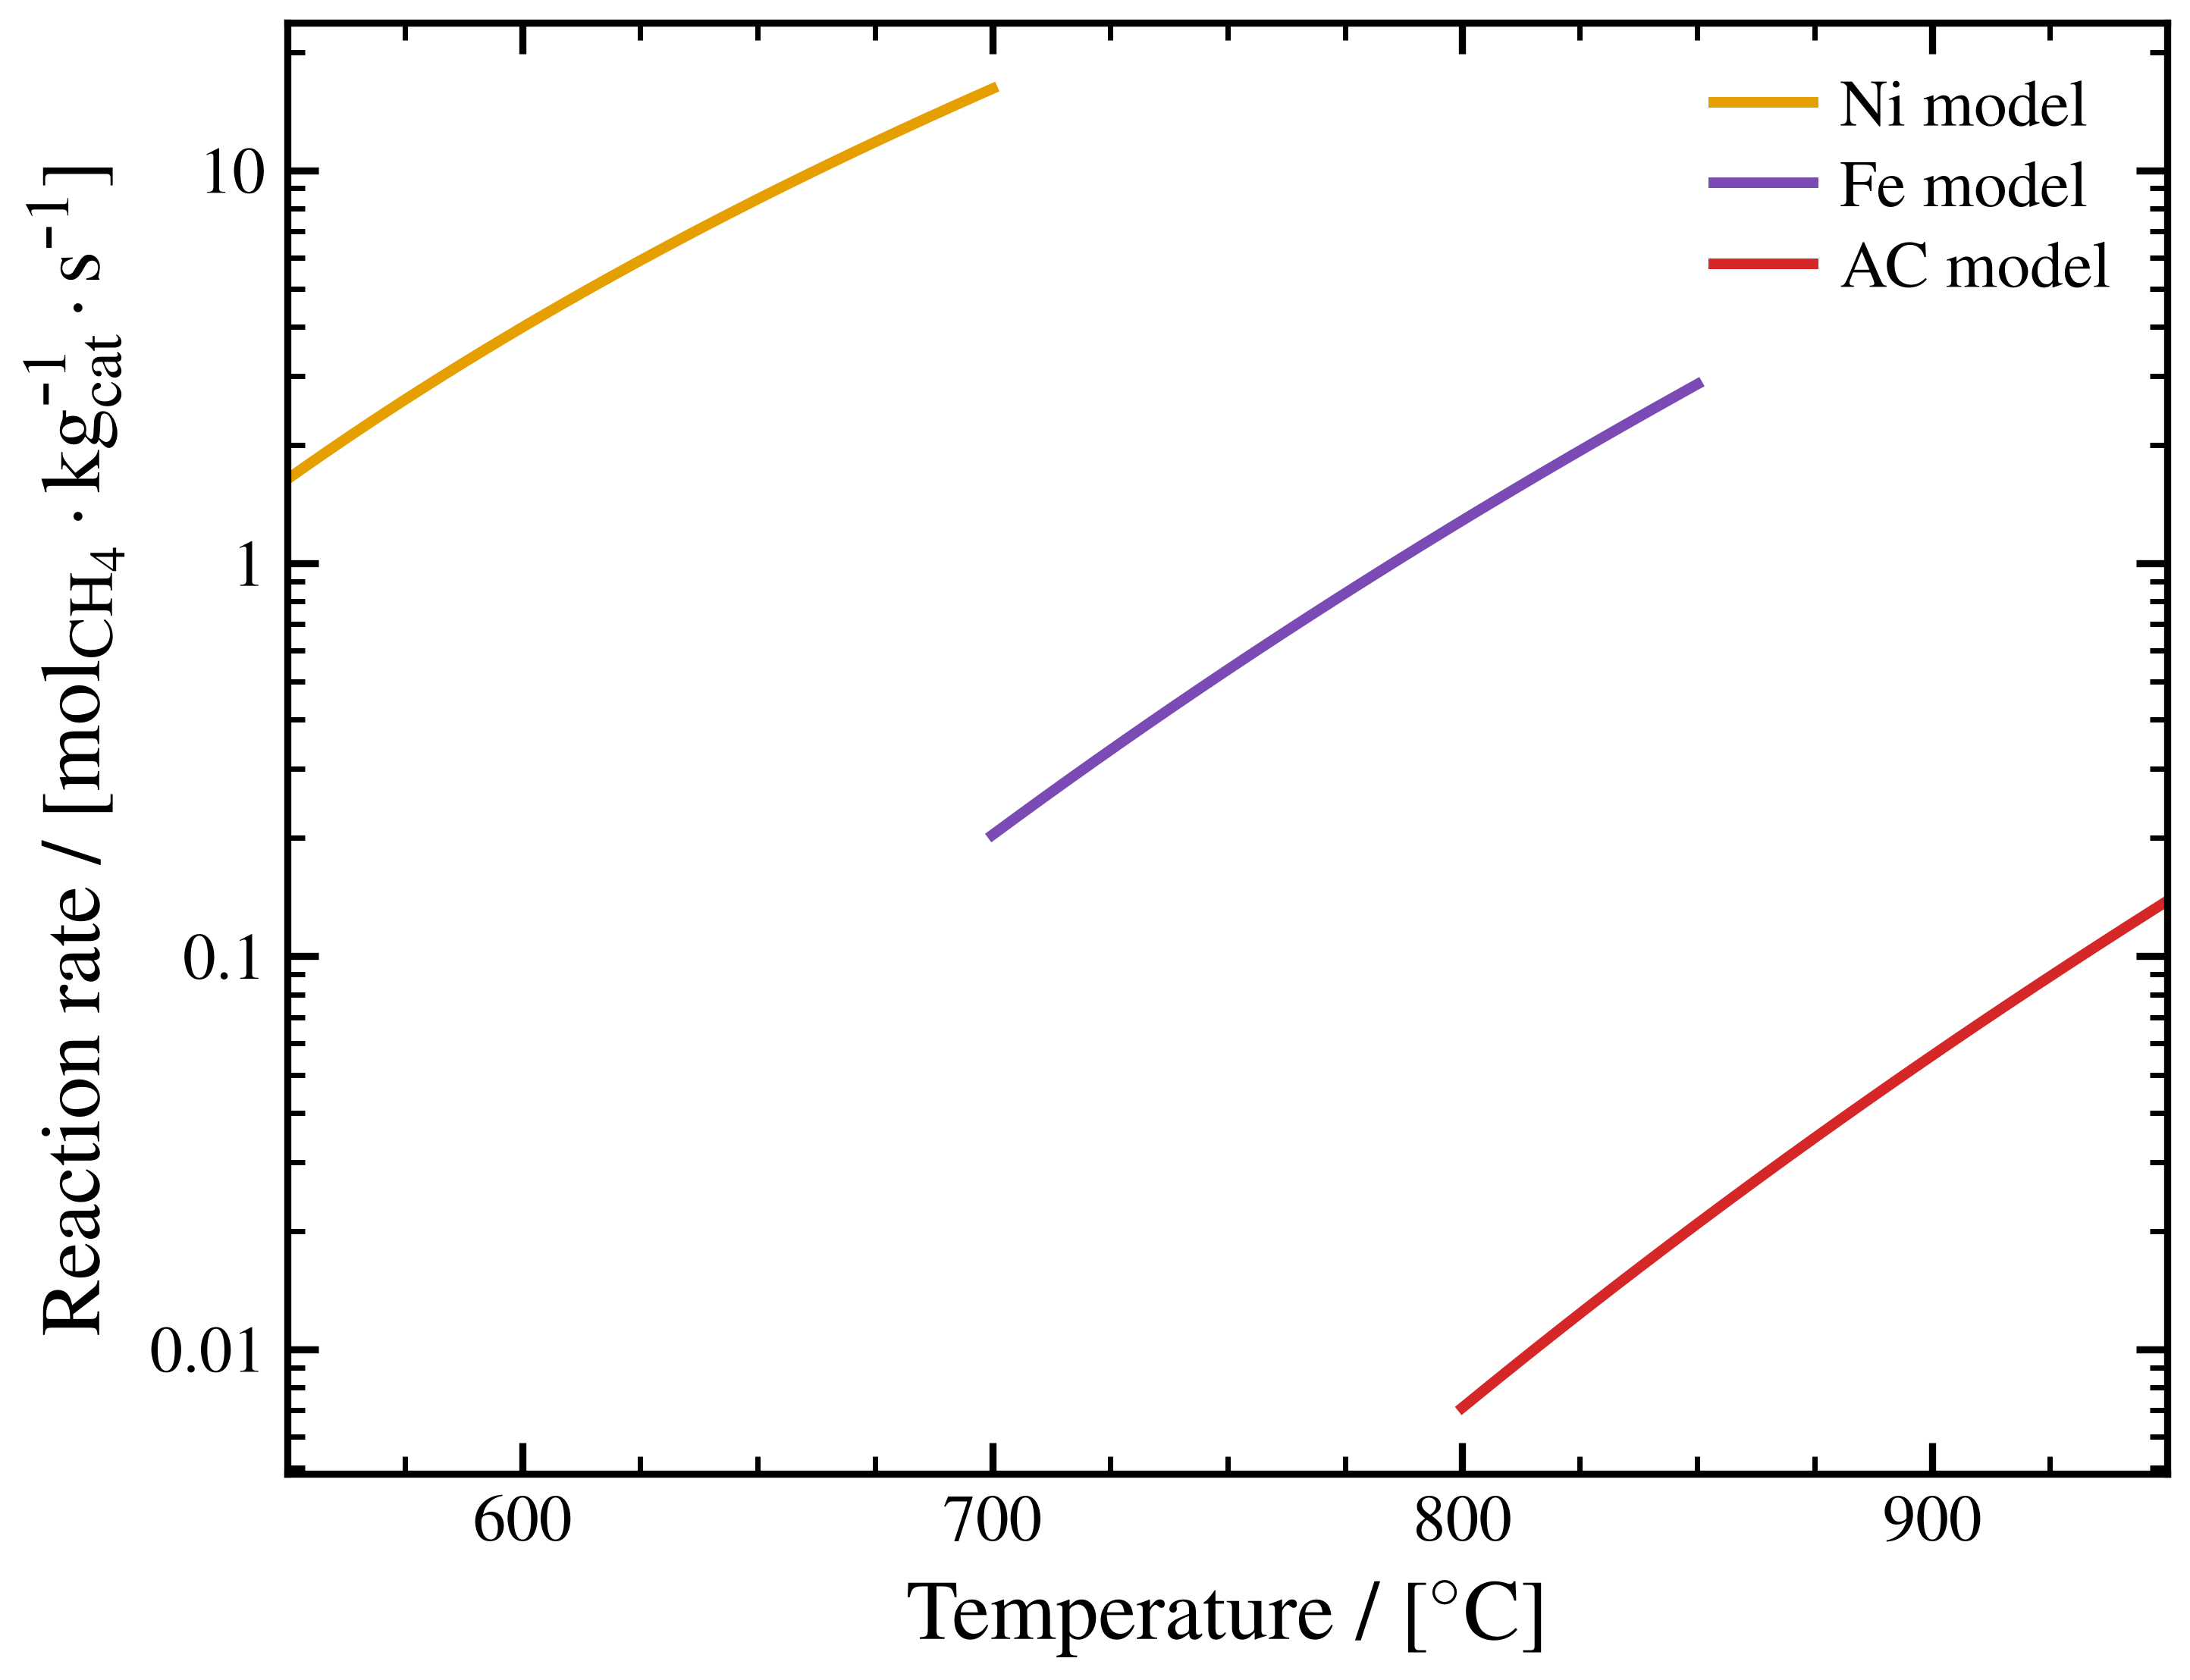


Ni model | 550-700 °C | min = 1.638746e+00 | max = 1.614101e+01
Fe Model   | 700-850 °C | min = 2.037313e-01 | max = 2.857629e+00
AC Model | 800-950 °C | min = 7.107424e-03 | max = 1.383615e-01


In [3]:
# PLOT: reaction rate vs. temperature at the baseline pressures

# Baseline pressures [bar]
P_CH4_bar = 1.0
P_H2_bar = 0

fig, ax = plt.subplots(figsize=(3.6 * scale_factor, 2.8 * scale_factor))

curves = draw_reaction_rates(ax, linewidth=1.2 * scale_factor,
                             P_CH4_bar=P_CH4_bar, P_H2_bar=P_H2_bar)

ax.set_xlabel(temperature_label, fontsize=axis_label_font)
ax.set_ylabel(rate_label, fontsize=axis_label_font)

# Inward ticks on all four sides
ax.tick_params(axis="both", which="both", direction="in", top=True, right=True, colors="black")
ax.tick_params(axis="both", which="major", labelsize=base_font,
               length=3.5 * scale_factor, width=0.8 * scale_factor)
ax.tick_params(axis="both", which="minor",
               length=2.0 * scale_factor, width=0.6 * scale_factor)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(0.8 * scale_factor)

ax.legend(fontsize=legend_font, loc="best", frameon=False,
          handlelength=1.5, handletextpad=0.4, borderpad=0.35, labelspacing=0.30)

fig.tight_layout(pad=0.8 * scale_factor)
fig.savefig("reaction_rate_vs_temperature.pdf", format="pdf")
plt.show()

# Numerical results
print()
for catalyst, name in [("Ni", "Ni model"), ("Fe", "Fe Model  "), ("AC", "AC Model")]:
    T_C, rate = curves[catalyst]
    print(f"{name} | {T_C[0]:.0f}-{T_C[-1]:.0f} °C | "
          f"min = {np.min(rate):.6e} | max = {np.max(rate):.6e}")